# ВШЭ 2026: Математические методы анализа данных

## Семинар 8: Градиентный бустинг

# Градиентный бустинг
Градиентный бустинг (Gradiend Boosting) — это алгоритм машинного обучения, разработанный в конце 90-х годов, который по-прежнему очень популярен. Он показывает наилучшие результаты для многих коммерческих (и академических) приложений. Градиентный бустинг строит ансамбль деревьев по одному, затем предсказания отдельных деревьев суммируются.


 В бустинге несколько слабых обучающихся (модели с высоким смещением и низкой дисперсией) объединяются аддитивно для создания ансамбля с уменьшенным смещением при сохранении низкой дисперсии.

## Градиентный бустинг против случайного леса

Прежде всего, нам нужно решить задачу:

Дана выборка из $\ell$ объектов с $d$ признаками. Найдите временну́ю асимптотику обучения и предсказания для композиции $a_N(x) = \sum_{n=0}^N b_n (x)$ над деревьями решений $b_n$ глубиной не более $D$.

#### Решение

Для обучения нам нужно подогнать $N$ деревьев, поэтому асимптотика будет $N * T_{tree}$, где $T_{tree}$ — сложность построения одного дерева решений. При построении одного дерева рассмотрим сложность нахождения оптимального разбиения в одной вершине. Рассмотрим, сколько времени тратится на построение одного уровня дерева решений. Обозначим через $\ell^i_j$ — количество объектов из обучающей выборки, достигающих вершины $j$ на $i$-м уровне.


Нам нужно перебрать $d$ признаков по $\ell^i_j - 1$ порогам. Вычисление метрики качества разбиения занимает $O (\ell^i_j)$ времени. Однако можно реализовать $\textit{оптимальный}$ алгоритм с предварительно вычисленной статистикой, который для каждого признака может вычислить метрику для всех $\ell^i_j - 1$ порогов за $O(\ell^i_j)$ времени. Следовательно, одна вершина требует $d * O (\ell^i_j) = O (d\ell^i_j)$ времени.

Очевидно, что $\ell^1_1 = \ell$, так как это корневая вершина. Далее, для любых $i, j$ верно, что $\ell^i_j = \ell^{i + 1}_{2j-1} + \ell^{i + 1}_{2j}$ по принципу сохранения потока (число объектов, переходящих из одной вершины в её дочерние, равно числу объектов, входящих в эту вершину). Отсюда следует, что в сумме на одном уровне будет только $\ell$ объектов, $\forall i ~:~ \sum\limits^{2^i}_{j=1} \ell^i_j = \ell$. Таким образом, для построения одного уровня дерева решений нужно только $ \sum \limits^{2^i}_{j=1} O (d\ell^i_j) = O (d\ell)$, а уровней только $D$. Следовательно, для построения одного дерева нужно $T_{tree} = O(Dd\ell)$ времени. У нас $N$ деревьев, поэтому общее время построения всех деревьев, а значит, и всего обучения: $O(NDd\ell)$

На этапе построения прогноза для объекта $x$ он "проходит" через дерево от корня до листьев, проходя путь не более чем из $D$ внутренних вершин, каждая из которых проверяет предикат за константное время. Следовательно, асимптотика построения предсказания для всей композиции — $O (ND)$.

### Изменение числа алгоритмов

Сравним, как ведут себя бустинг и бэггинг при росте числа базовых моделей.

В случае бэггинга все базовые алгоритмы настраиваются на разные выборки из одного распределения на $\mathbb{X} \times \mathbb{Y}$. При этом некоторые из них могут быть переобучены, но усреднение позволяет ослабить этот эффект (из-за того, что для некоррелированных алгоритмов разброс композиции в $N$ раз меньше разброса отдельных алгоритмов, то есть много деревьев с меньшей вероятностью подстроятся под какой-то нетипичный объект по сравнению с одним деревом). Если $N$ достаточно велико, то последующее добавление новых алгоритмов уже не улучшит качество модели.

В случае бустинга каждый алгоритм настраивается на ошибки всех предыдущих, что позволяет всё точнее подстраиваться под исходное распределение на каждом шаге. Однако при достаточно большом $N$ это является источником переобучения, так как последующее добавление новых алгоритмов будет продолжать подстраиваться под обучающую выборку, уменьшая ошибку на ней, но снижая обобщающую способность итоговой композиции.

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

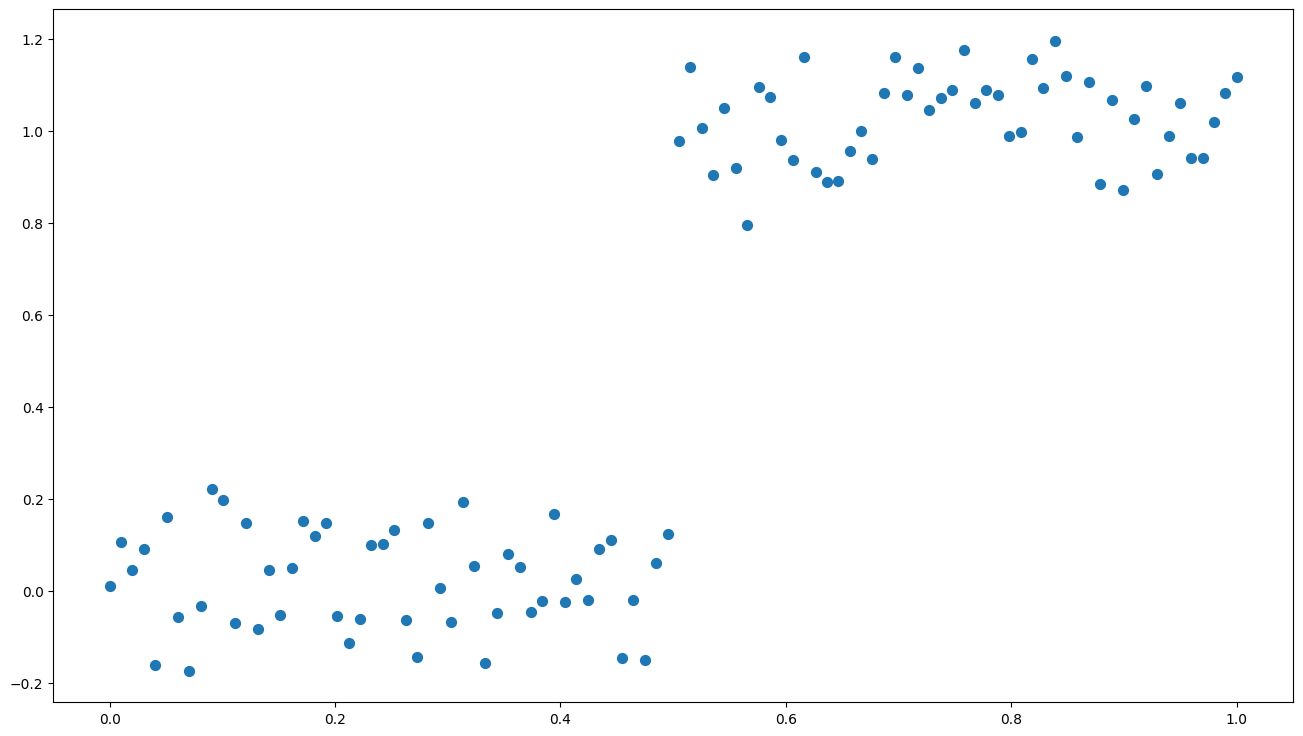

In [3]:
X_train = np.linspace(0, 1, 100)
X_test = np.linspace(0, 1, 1000)

@np.vectorize
def target(x):
    return x > 0.5

Y_train = target(X_train) + np.random.randn(*X_train.shape) * 0.1

plt.figure(figsize = (16, 9))
plt.scatter(X_train, Y_train, s=50);

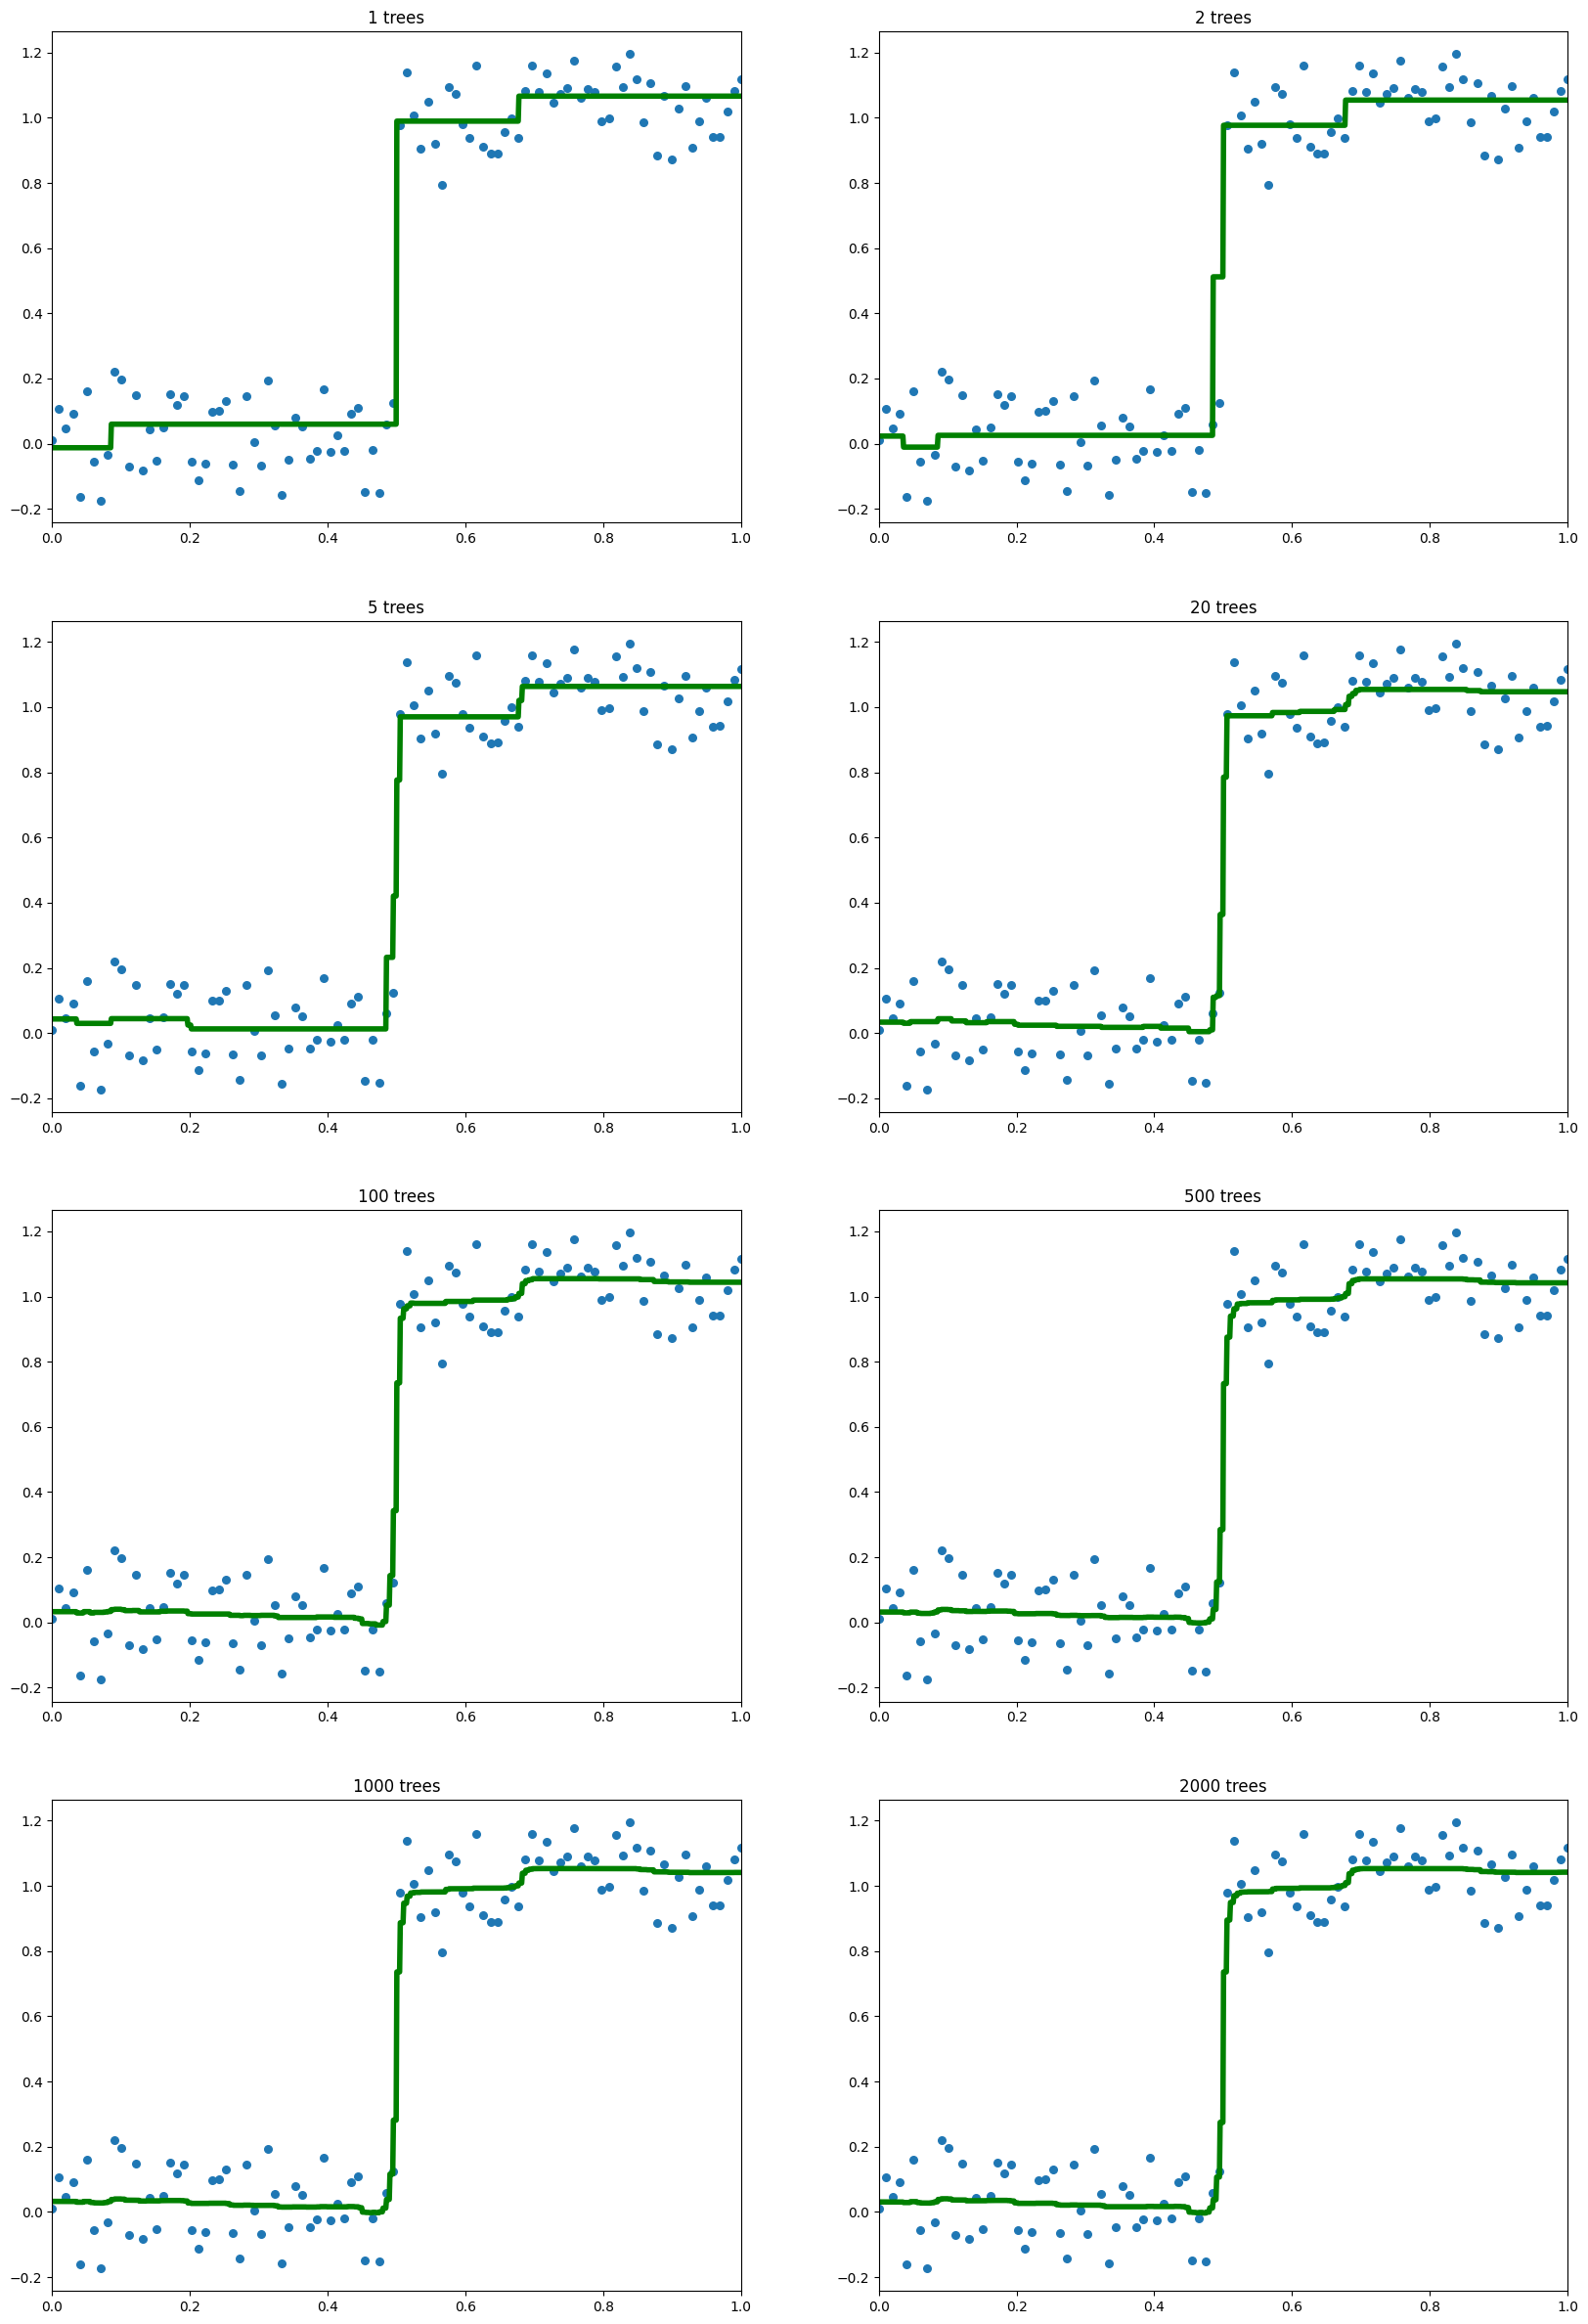

In [4]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor

reg = BaggingRegressor(DecisionTreeRegressor(max_depth=2), warm_start=True)
plt.figure(figsize=(20, 30))
sizes = [1, 2, 5, 20, 100, 500, 1000, 2000]
for i, s in enumerate(sizes):
    reg.n_estimators = s
    reg.fit(X_train.reshape(-1, 1), Y_train)
    plt.subplot(4, 2, i+1)
    plt.xlim([0, 1])
    plt.scatter(X_train, Y_train, s=30)
    plt.plot(X_test, reg.predict(X_test.reshape(-1, 1)), c='green', linewidth=4)
    plt.title('{} trees'.format(s))

Видно, что начиная с некоторого момента итоговая функция перестаёт меняться при росте числа деревьев.

Теперь сделаем то же самое для градиентного бустинга.

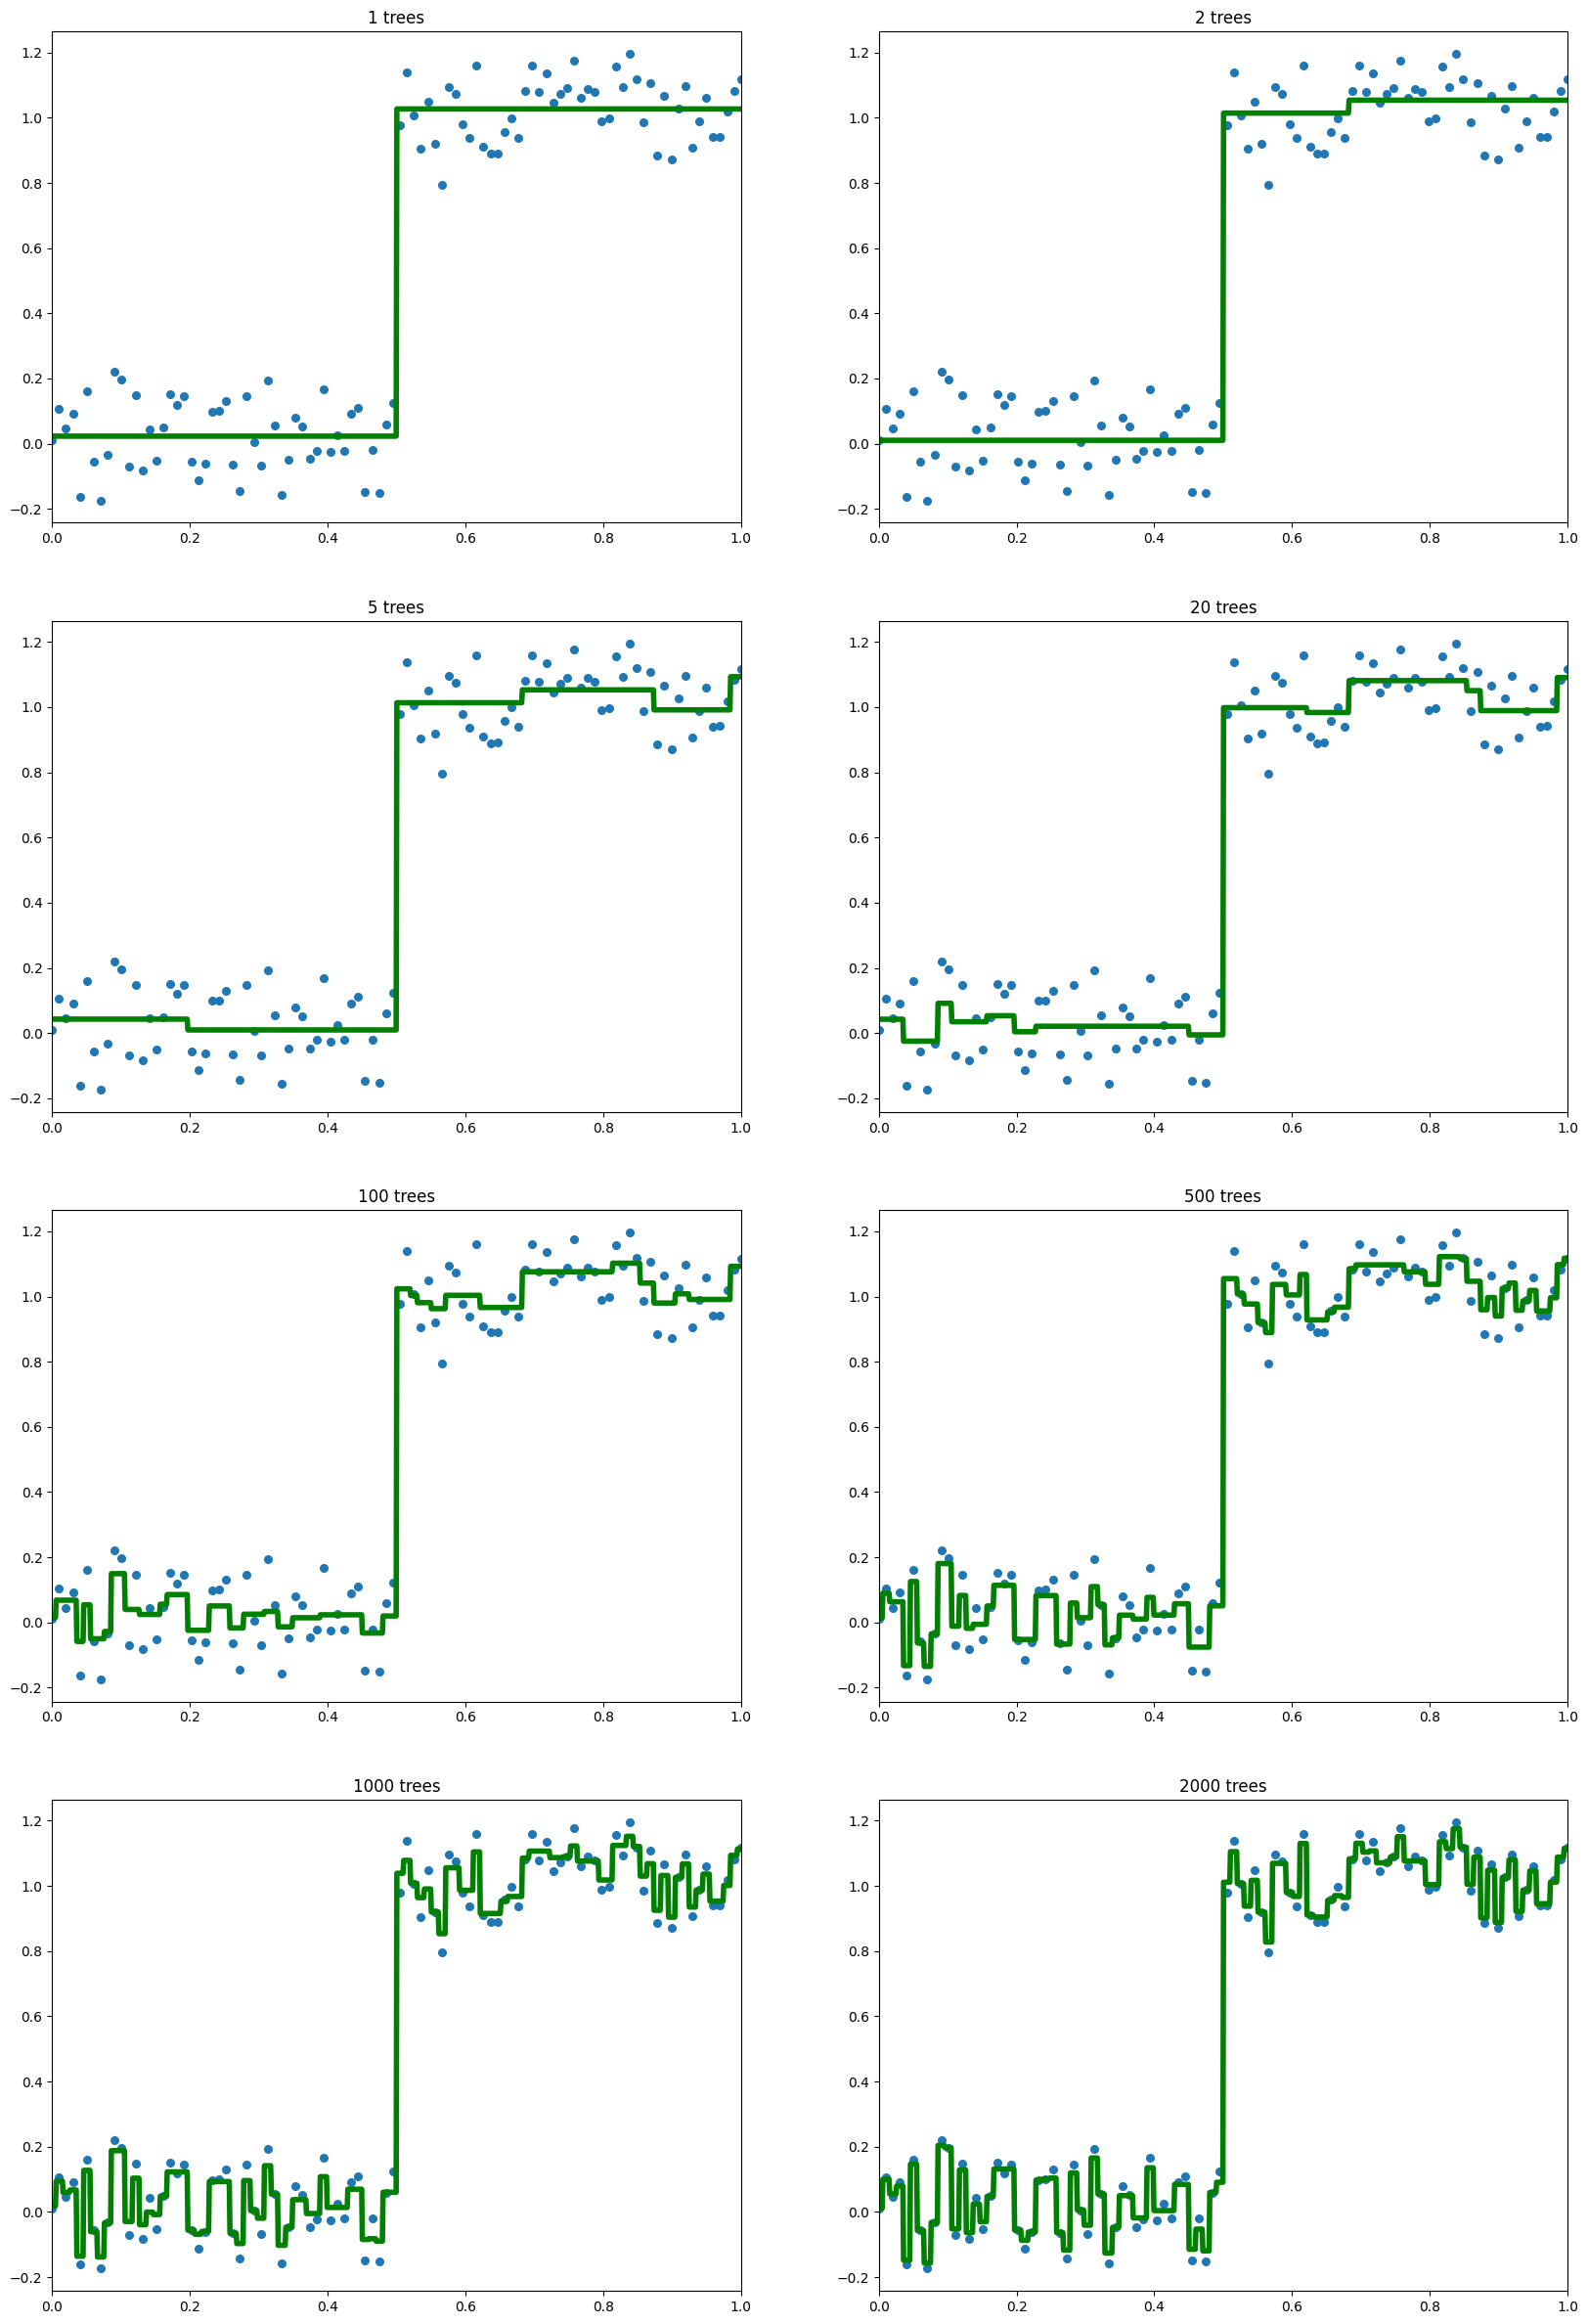

In [5]:
reg = GradientBoostingRegressor(max_depth=1, learning_rate=1, warm_start=True)
plt.figure(figsize=(20, 30))
sizes = [1, 2, 5, 20, 100, 500, 1000, 2000]
for i, s in enumerate(sizes):
    reg.n_estimators = s
    reg.fit(X_train.reshape(-1, 1), Y_train)
    plt.subplot(4, 2, i+1)
    plt.xlim([0, 1])
    plt.scatter(X_train, Y_train, s=30)
    plt.plot(X_test, reg.predict(X_test.reshape(-1, 1)), c='green', linewidth=4)
    plt.title('{} trees'.format(s))

Градиентный бустинг быстро находит истинную зависимость, после чего начинает подстраиваться под конкретные объекты обучающей выборки, то есть сильно переобучается.

Для решения этой проблемы можно выбрать очень простой базовый алгоритм или
искусственно уменьшить вес новых алгоритмов, используя шаг $\eta$:
$$a_N(x) = \sum_{n=0}^N \eta \gamma_N b_n(x).$$

Эта корректировка замедляет обучение по сравнению с бэггингом, но позволяет снизить переобучение. Однако важно понимать, что переобучение всё равно будет происходить при обучении произвольно большого числа базовых алгоритмов при фиксированном $\eta$.

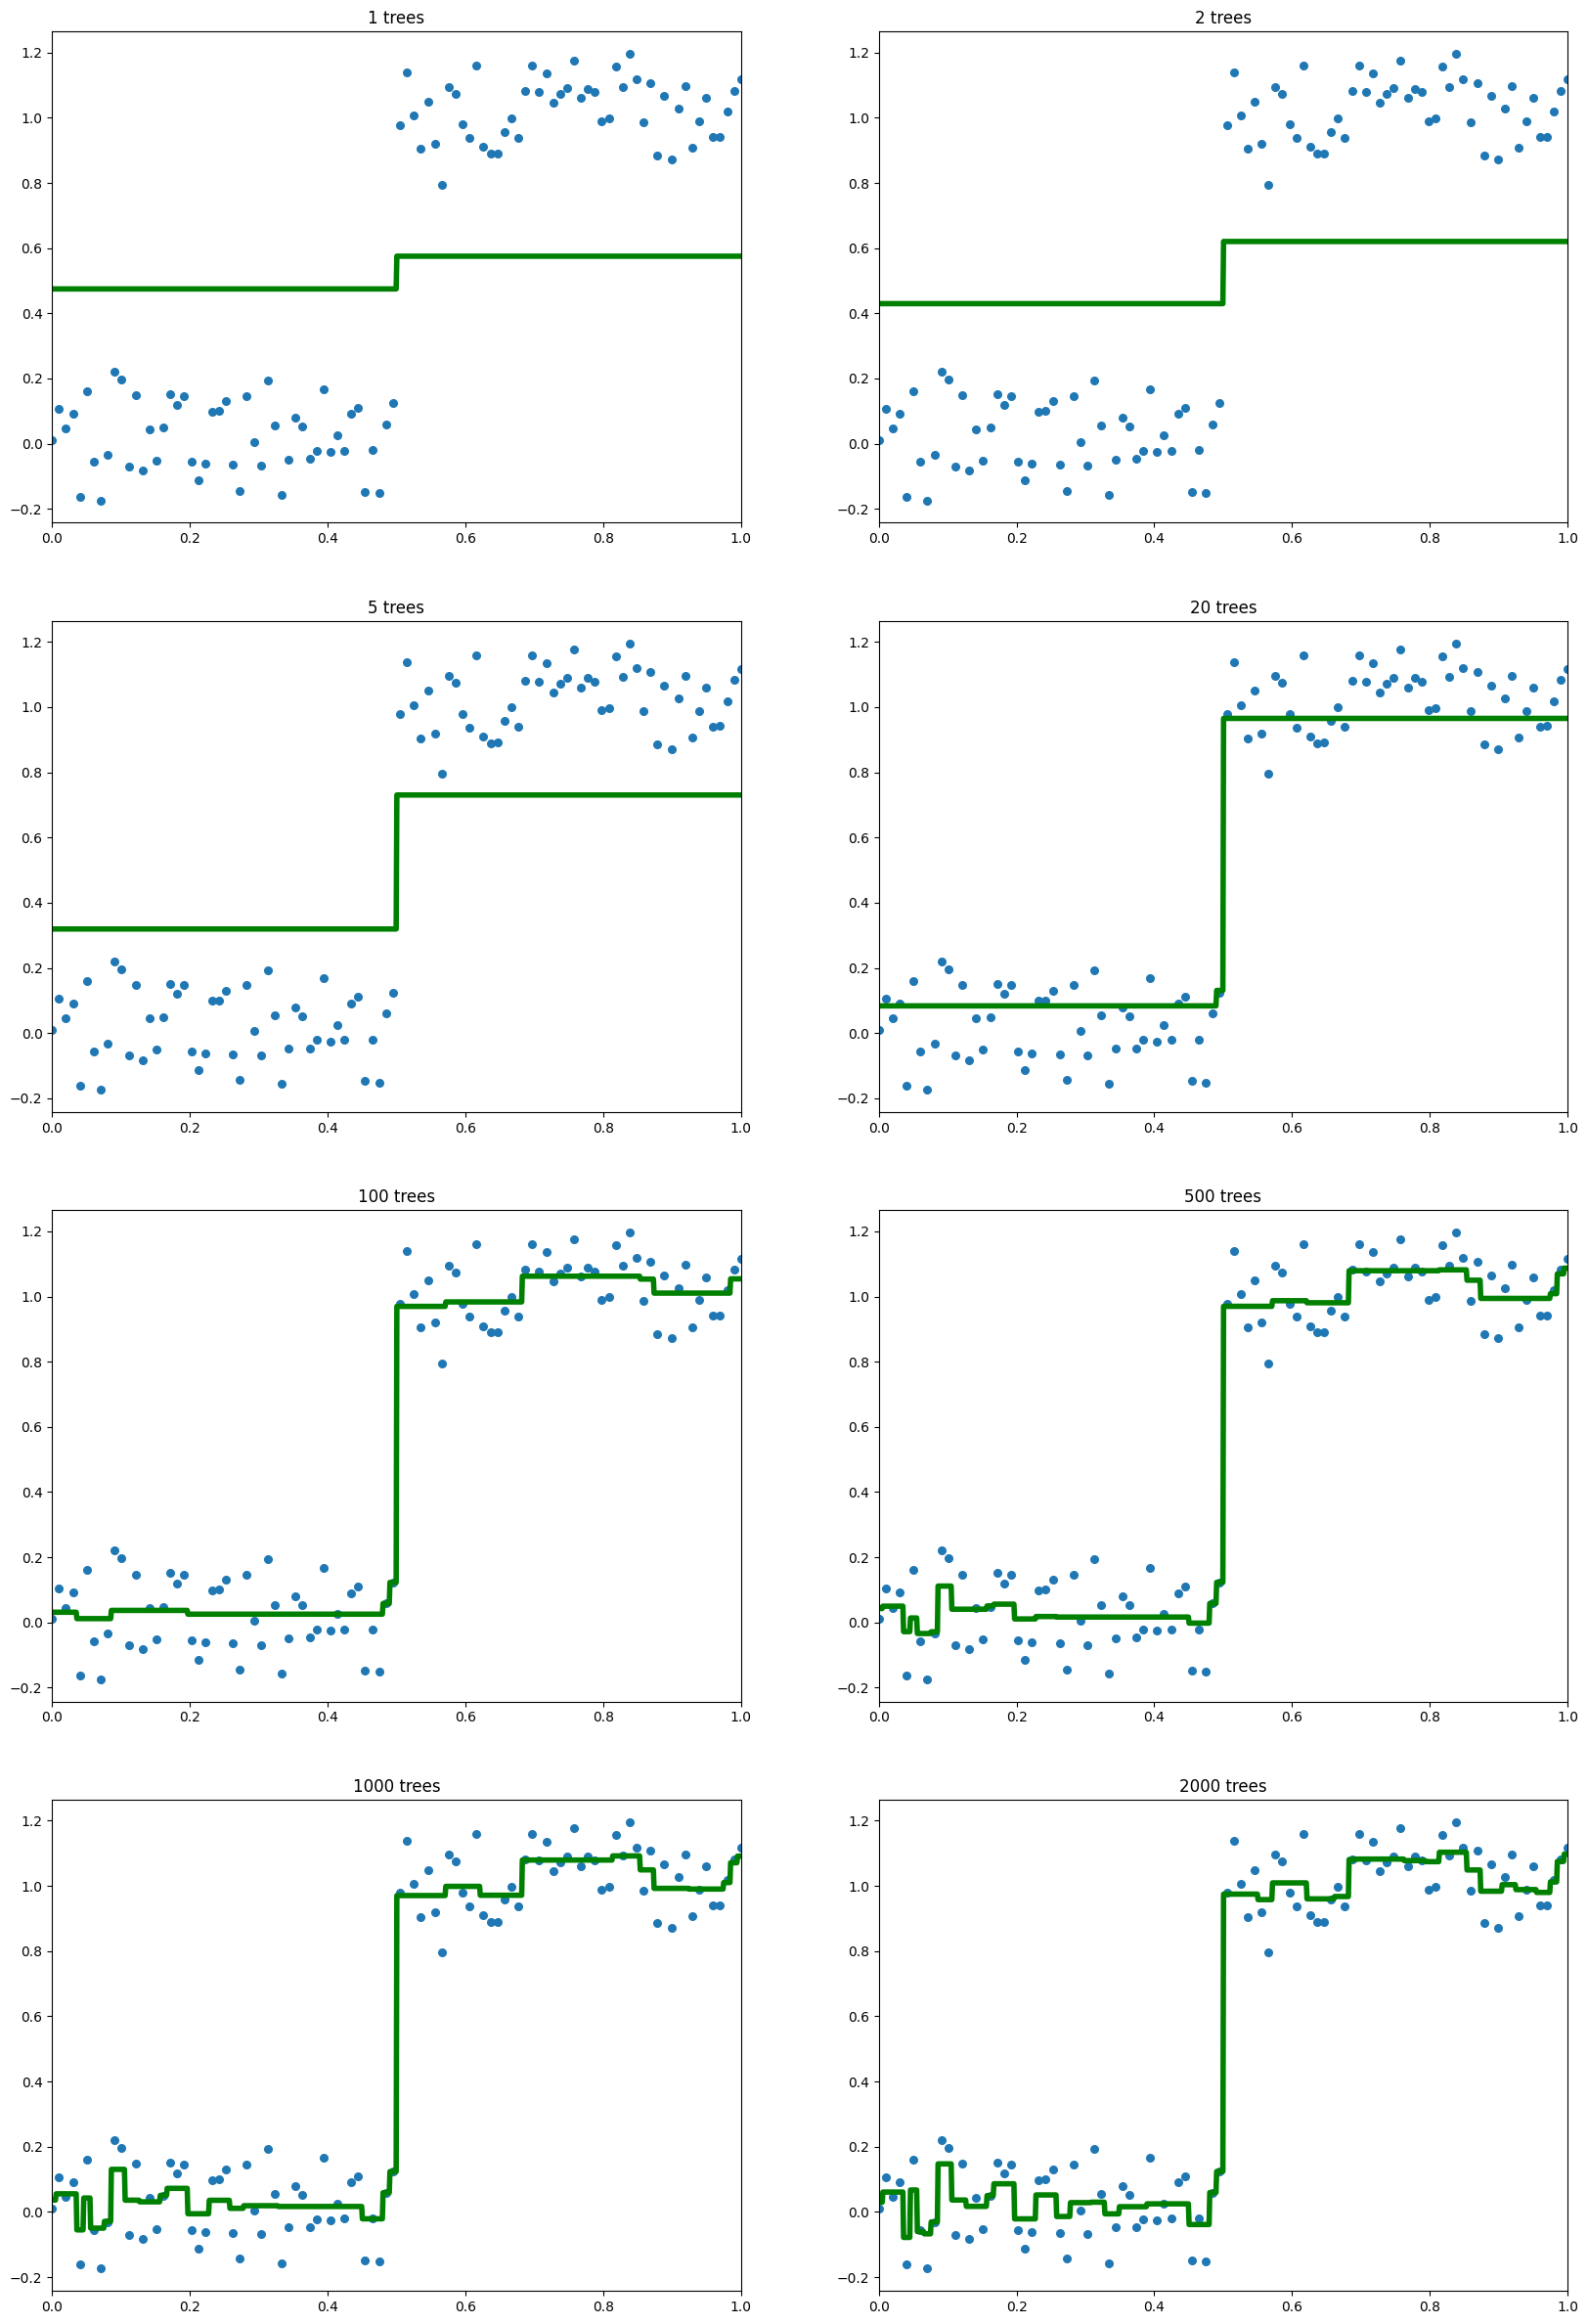

In [6]:
reg = GradientBoostingRegressor(max_depth=1, learning_rate=0.1, warm_start=True)
plt.figure(figsize=(20, 30))
sizes = [1, 2, 5, 20, 100, 500, 1000, 2000]
for i, s in enumerate(sizes):
    reg.n_estimators = s
    reg.fit(X_train.reshape(-1, 1), Y_train)
    plt.subplot(4, 2, i+1)
    plt.xlim([0, 1])
    plt.scatter(X_train, Y_train, s=30)
    plt.plot(X_test, reg.predict(X_test.reshape(-1, 1)), c='green', linewidth=4)
    plt.title('{} trees'.format(s))

Теперь проверим описанный выше эффект на реальных данных.

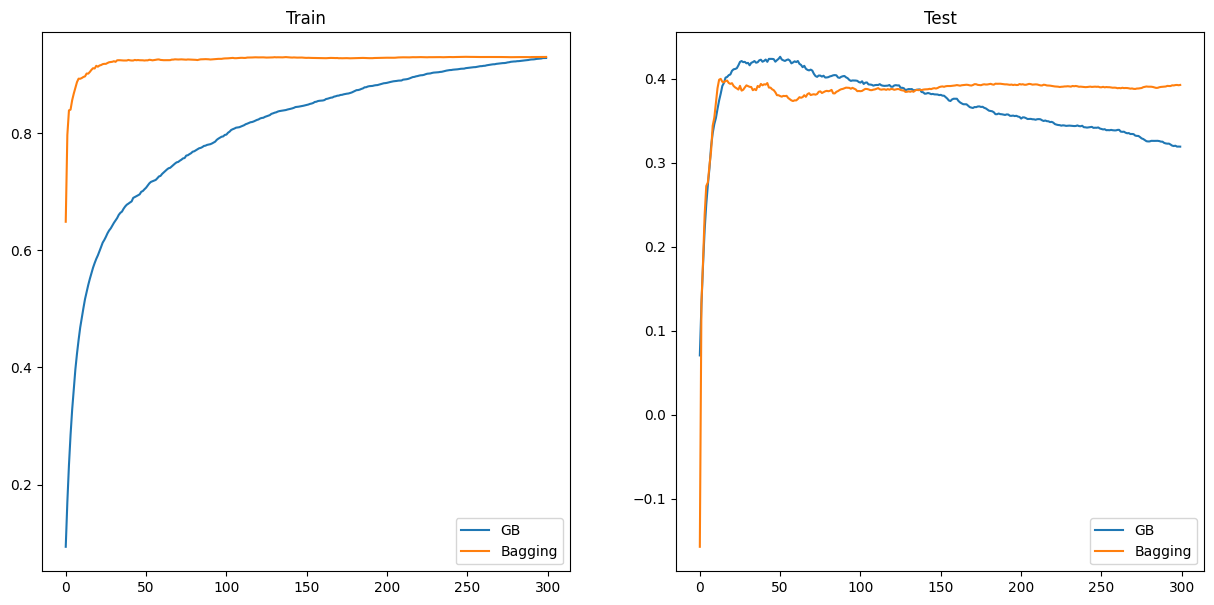

In [7]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

ds = datasets.load_diabetes()
X = ds.data
Y = ds.target
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.5, test_size=0.5)

MAX_ESTIMATORS = 300

gbclf = BaggingRegressor(warm_start=True)
err_train_bag = []
err_test_bag = []
for i in range(1, MAX_ESTIMATORS+1):
    gbclf.n_estimators = i
    gbclf.fit(X_train, Y_train)
    err_train_bag.append(gbclf.score(X_train, Y_train)) # R2 returning
    err_test_bag.append(gbclf.score(X_test, Y_test)) # R2 returning

gbclf = GradientBoostingRegressor(warm_start=True, max_depth=2, learning_rate=0.1)
err_train_gb = []
err_test_gb = []
for i in range(1, MAX_ESTIMATORS+1):
    gbclf.n_estimators = i
    gbclf.fit(X_train, Y_train)
    err_train_gb.append(gbclf.score(X_train, Y_train)) # R2 returning
    err_test_gb.append(gbclf.score(X_test, Y_test)) # R2 returning

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(err_train_gb, label='GB')
plt.plot(err_train_bag, label='Bagging')
plt.legend()
plt.title('Train')
plt.subplot(1, 2, 2)
plt.plot(err_test_gb, label='GB')
plt.plot(err_test_bag, label='Bagging')
plt.legend()
plt.title('Test')
plt.gcf().set_size_inches(15,7)

## Качество алгоритмов

Сравним поведение двух методов. Для этого построим композицию алгоритмов над деревьями решений на задаче [Kaggle: Predicting a Biological Response](https://www.kaggle.com/c/bioresponse)

Данные представлены в формате CSV (значения, разделённые запятыми). Каждая строка в этом наборе данных представляет одну молекулу.

Первый столбец *(целевая переменная)* содержит экспериментальные данные, описывающие реальный биологический отклик; молекула вызывала этот отклик (1) или нет (0).

Оставшиеся столбцы *(признаки)* представляют молекулярные дескрипторы (d1–d1776) — вычисленные свойства, которые могут отражать некоторые характеристики молекулы, например размер, форму или элементный состав. Матрица дескрипторов нормализована.


In [8]:
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# https://drive.google.com/file/d/1yAOlsXMjSjI-XPwMGFq3PU6BKlib1xha
data = pd.read_csv('https://github.com/darkydash/ml_hse_2024/raw/refs/heads/main/week09/train.csv')
data.head()

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0


In [9]:
X = data.iloc[:, 1:].values
y = data.iloc[:, 0].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.8, random_state=241)

In [10]:
%%time
gbm = GradientBoostingClassifier(
    n_estimators=250, learning_rate=0.2, verbose=True
).fit(X_train, y_train)

      Iter       Train Loss   Remaining Time 
         1           1.2613           24.35s
         2           1.1713           26.01s
         3           1.1007           25.28s
         4           1.0524           23.92s
         5           1.0125           23.00s
         6           0.9736           22.43s
         7           0.9441           22.07s
         8           0.9194           22.06s
         9           0.8950           21.90s
        10           0.8786           21.64s
        20           0.7166           19.76s
        30           0.5979           18.71s
        40           0.5150           17.89s
        50           0.4578           16.02s
        60           0.3984           14.52s
        70           0.3420           13.29s
        80           0.3078           12.26s
        90           0.2588           11.27s
       100           0.2241           10.41s
       200           0.0767            3.21s
CPU times: user 16.6 s, sys: 26.7 ms, total: 16.6 s
Wa

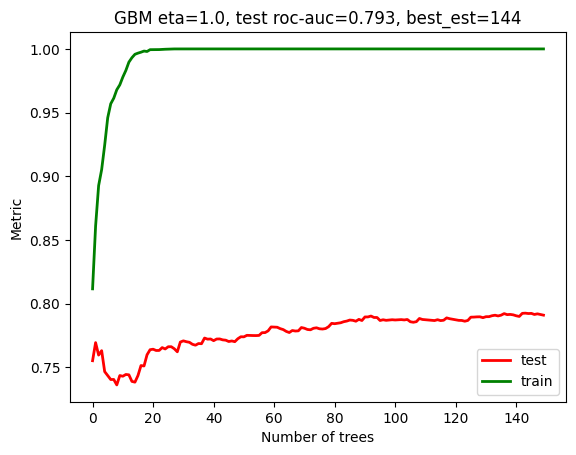

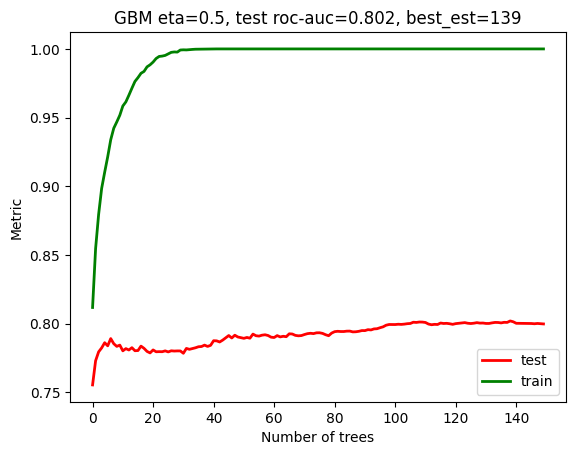

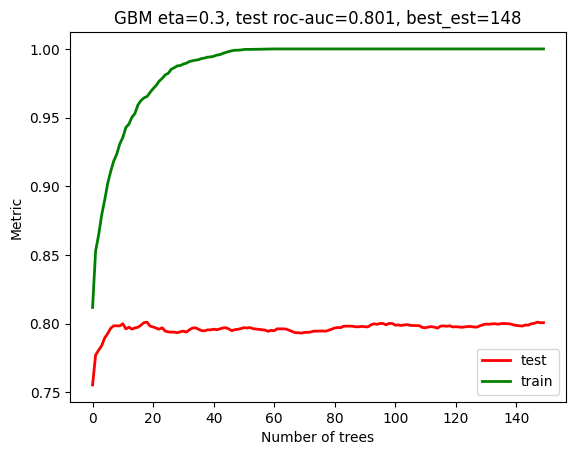

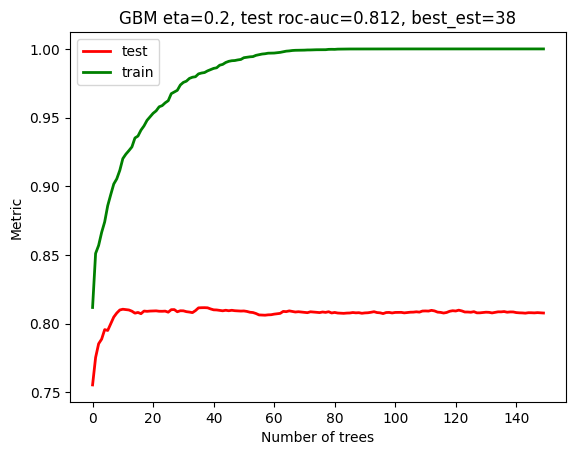

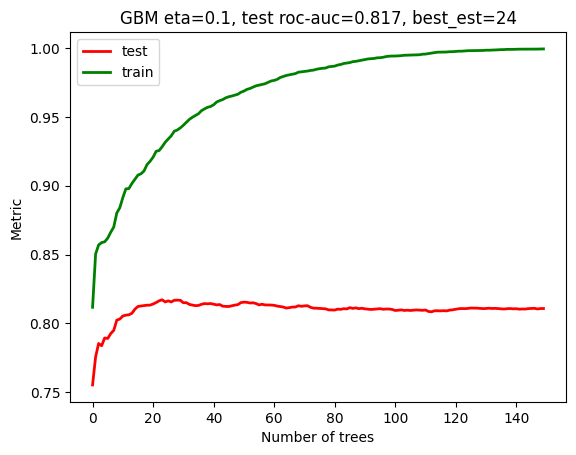

In [11]:
from sklearn.metrics import roc_auc_score

for learning_rate in [1, 0.5, 0.3, 0.2, 0.1]:

    gbm = GradientBoostingClassifier(
        n_estimators=150, learning_rate=learning_rate, random_state=241
    ).fit(X_train, y_train)

    test_deviance = np.zeros((gbm.n_estimators,), dtype=np.float64)
    for i, y_pred in enumerate(gbm.staged_decision_function(X_test)):
        test_deviance[i] = roc_auc_score(y_test, y_pred)

    train_deviance = np.zeros((gbm.n_estimators,), dtype=np.float64)
    for i, y_pred in enumerate(gbm.staged_decision_function(X_train)):
        train_deviance[i] = roc_auc_score(y_train, y_pred)

    plt.figure()
    plt.plot(test_deviance, 'r', linewidth=2)
    plt.plot(train_deviance, 'g', linewidth=2)
    plt.legend(['test', 'train'])

    plt.title('GBM eta=%.1f, test roc-auc=%.3f, best_est=%d' % (
        learning_rate, test_deviance.max(), test_deviance.argmax()+1)
             )
    plt.xlabel('Number of trees')
    plt.ylabel('Metric')

Итого, лучшая композиция строится при $\eta = 0.1$. Она включает 24 базовых алгоритма и достигает значения 0.817 на контрольной выборке. При этом случайный лес с тем же числом базовых алгоритмов уступает градиентному бустингу:


In [12]:
rf = RandomForestClassifier(n_estimators=24, random_state=0).fit(X_train, y_train)
print ('Train RF ROC-AUC =', roc_auc_score(y_train, rf.predict_proba(X_train)[:,1]))
print ('Test RF ROC-AUC = ', roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]))

Train RF ROC-AUC = 0.9999786482947104
Test RF ROC-AUC =  0.8037501166053144


Заметим также, что при всём этом случайный лес, в отличие от градиентного бустинга, использует глубокие деревья, требующие вычислительных ресурсов для их обучения.

Чтобы достичь такого же качества, случайному лесу требуется значительно большее число базовых алгоритмов:


In [13]:
for n_estimators in range(10, 101, 10):
    rf = RandomForestClassifier(
        n_estimators=n_estimators, n_jobs=4).fit(X_train, y_train
                                                )
    print (
        n_estimators, 'trees: train ROC-AUC =',
        roc_auc_score(y_train, rf.predict_proba(X_train)[:,1]),
        'test ROC-AUC =',
        roc_auc_score(y_test, rf.predict_proba(X_test)[:,1])
    )

10 trees: train ROC-AUC = 0.9995943175994989 test ROC-AUC = 0.776906003559153
20 trees: train ROC-AUC = 0.9998042760348459 test ROC-AUC = 0.8073926872322562
30 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8147220039609927
40 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8118192043570922
50 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8176239066009371
60 trees: train ROC-AUC = 0.9999999999999999 test ROC-AUC = 0.8201712842371142
70 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8199656552501094
80 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8177331119626288
90 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8277562356934249
100 trees: train ROC-AUC = 1.0 test ROC-AUC = 0.8244820930115744


Наконец, можно посмотреть [визуализацию](http://arogozhnikov.github.io/2016/06/24/gradient_boosting_explained.html) градиентного бустинга для деревьев решений разной глубины для функций разных типов.


## Современные библиотеки градиентного бустинга

Ранее мы использовали наивную версию градиентного бустинга из scikit-learn, [изобретённую](https://projecteuclid.org/download/pdf_1/euclid.aos/1013203451) в 1999 году Фридманом. С тех пор было предложено множество реализаций, которые на практике показывают лучшие результаты. На сегодняшний день существуют три популярные библиотеки, реализующие градиентный бустинг:
* XGBoost. После своего выхода быстро набрала популярность и оставалась стандартом до конца 2016 года. Особенности этой библиотеки обсуждались на лекции.
* LightGBM. Отличительная особенность — скорость построения композиции. Например, для ускорения обучения используется следующий приём: при построении вершины дерева вместо перебора всех значений признака перебираются значения гистограммы этого признака. Таким образом, вместо $O (\ell)$ требуется $O$(#бинов). Кроме того, в отличие от других библиотек, строящих дерево по уровням, LightGBM использует стратегию best-first, то есть на каждом шаге строится вершина, дающая наибольшее уменьшение функционала. Таким образом, каждое дерево представляет собой цепочку с прикреплёнными листьями, поэтому ограничение на num_leaves является более значимым.
* CatBoost. Библиотека от Яндекса. Позволяет автоматически обрабатывать категориальные признаки. Кроме того, алгоритм менее чувствителен к выбору конкретных гиперпараметров, что сокращает время, которое человек тратит на подбор оптимальных гиперпараметров.


### Базовые параметры

(lightgbm/catboost)

* objective — функционал, под который будет настраиваться композиция
* eta / learning_rate — скорость обучения
* num_iterations / n_estimators — количество итераций бустинга

#### Параметры, отвечающие за сложность деревьев
* max_depth — максимальная глубина
* max_leaves / num_leaves — максимальное количество вершин в дереве
* gamma / min_gain_to_split — порог уменьшения функции ошибки при разбиении в дереве
* min_data_in_leaf — минимальное количество объектов в листе
* min_sum_hessian_in_leaf — минимальная сумма весов объектов в листе, минимальное количество объектов, при котором выполняется разбиение
* lambda — коэффициент регуляризации (L2)
* subsample / bagging_fraction — какую долю обучающих объектов использовать для построения одного дерева
* colsample_bytree / feature_fraction — какую долю признаков использовать для построения одного дерева

Подбор всех этих параметров — настоящее искусство. Но начать настройку можно с наиболее важных параметров: learning_rate и n_estimators. Обычно один из них фиксируется, а второй из этих двух параметров подбирается (например, фиксируется n_estimators=1000 и подбирается learning_rate). Следующим по важности является max_depth. Поскольку нас интересуют неглубокие деревья, его обычно перебирают в диапазоне [3; 7].


In [14]:
!pip install catboost --quiet
!pip install lightgbm --quiet

<b>ВНИМАНИЕ:</b> на Mac для корректной работы lightgbm может потребоваться дополнительная установка libomp; проще всего через brew: <br>
`brew install libomp` <br>
Справочная информация здесь: <br>
https://stackoverflow.com/questions/44937698/lightgbm-oserror-library-not-loaded


In [15]:
from sklearn.datasets import make_classification
from matplotlib.colors import ListedColormap
from tqdm import tqdm

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

def plot_surface(X, y, clf):
    h = 0.2
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])

    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(8, 8))
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

    # Также отобразить обучающие точки
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

X, y = make_classification(n_samples=500, n_features=2, n_informative=2,
                           n_redundant=0, n_repeated=0,
                           n_classes=2, n_clusters_per_class=2,
                           flip_y=0.05, class_sep=0.8, random_state=241)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=241
)

## CatBoost


0.919452347083926


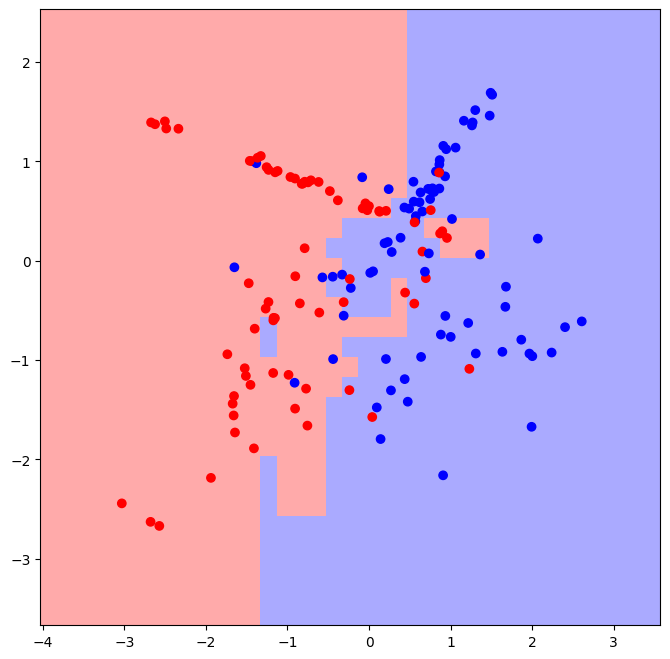

In [16]:
from catboost import CatBoostClassifier

clf = CatBoostClassifier(iterations=300, logging_level='Silent')
clf.fit(X_train, y_train)
plot_surface(X_test, y_test, clf)

print(roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]))

Рассмотрим примеры работы этих библиотек на датасете [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset)


В нём есть два категориальных признака — `gender` и `smoking_history`


In [17]:
data = pd.read_csv('https://github.com/darkydash/ml_hse_2024/raw/refs/heads/main/week09/diabetes_prediction_dataset.csv')

X_cat = data.drop('diabetes', axis=1)
y = data['diabetes']

X_train_cat, X_test_cat, y_train, y_test = train_test_split(
    X_cat, y, test_size=0.3, random_state=241
)

X_train_cat.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
26977,Female,45.0,0,0,No Info,23.71,6.2,80
56535,Male,44.0,0,0,former,26.91,4.0,155
7415,Male,71.0,0,0,never,27.32,6.2,80
69398,Female,51.0,0,0,never,24.54,6.6,100
10320,Male,37.0,0,0,not current,27.32,4.8,90


Как упоминалось ранее, `CatBoost` может автоматически обрабатывать категориальные признаки


100%|██████████| 11/11 [01:29<00:00,  8.18s/it]


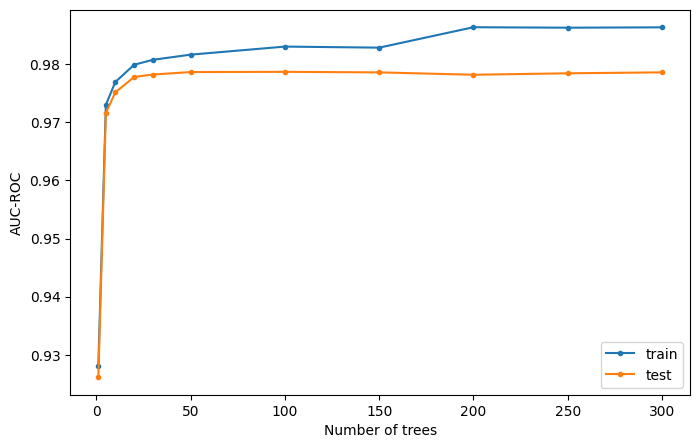

In [18]:
n_trees = [1, 5, 10, 20, 30, 50, 100, 150, 200, 250, 300]
quals_train = []
quals_test = []
for n in tqdm(n_trees):
    clf = CatBoostClassifier(iterations=n,
                             cat_features=['gender', 'smoking_history'], # явно задано, какие столбцы являются категориальными
                             logging_level='Silent')
    clf.fit(X_train_cat, y_train)
    q_train = roc_auc_score(y_train, clf.predict_proba(X_train_cat)[:, 1])
    q_test = roc_auc_score(y_test, clf.predict_proba(X_test_cat)[:, 1])
    quals_train.append(q_train)
    quals_test.append(q_test)

plt.figure(figsize=(8, 5))
plt.plot(n_trees, quals_train, marker='.', label='train')
plt.plot(n_trees, quals_test, marker='.', label='test')
plt.xlabel('Number of trees')
plt.ylabel('AUC-ROC')
plt.legend()

plt.show()

## LightGBM


Если при запуске ячейки ниже на Mac возникает ошибка, возможно, потребуется установить libomp; проще всего через brew: <br>
`brew install libomp` <br>
Справочная информация здесь: <br>
https://stackoverflow.com/questions/44937698/lightgbm-oserror-library-not-loaded


В случае если `LightGBM` кодирует категориальные признаки с помощью `OneHotEncoder`


In [19]:
X_lgb = data.drop('diabetes', axis=1)
X_lgb = pd.get_dummies(X_lgb, columns=['gender', 'smoking_history'])

X_train_lgb, X_test_lgb, y_train, y_test = train_test_split(
    X_lgb, y, test_size=0.3, random_state=241
)

X_train_lgb.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
26977,45.0,0,0,23.71,6.2,80,True,False,False,True,False,False,False,False,False
56535,44.0,0,0,26.91,4.0,155,False,True,False,False,False,False,True,False,False
7415,71.0,0,0,27.32,6.2,80,False,True,False,False,False,False,False,True,False
69398,51.0,0,0,24.54,6.6,100,True,False,False,False,False,False,False,True,False
10320,37.0,0,0,27.32,4.8,90,False,True,False,False,False,False,False,False,True


In [20]:
from lightgbm import LGBMClassifier

lgb_params = {"verbose": -1} # disable verbose
clf_lgb = LGBMClassifier(n_estimators=300, n_jobs=1, **lgb_params) #n_jobs имеет значение 1, чтобы предотвратить
                                                                    #зависание при использовании определенных компиляторов
clf_lgb.fit(X_train_lgb, y_train)

print(roc_auc_score(y_test, clf_lgb.predict_proba(X_test_lgb)[:, 1]))

0.9774245430719558


Снова выберем оптимальное количество деревьев


100%|██████████| 11/11 [00:12<00:00,  1.15s/it]


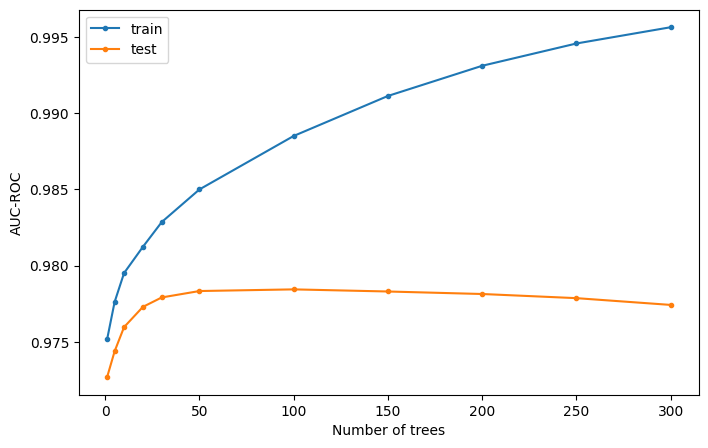

In [21]:
n_trees = [1, 5, 10, 20, 30, 50, 100, 150, 200, 250, 300]
quals_train = []
quals_test = []
for n in tqdm(n_trees):
    clf = LGBMClassifier(n_estimators=n, n_jobs=1, **lgb_params)
    clf.fit(X_train_lgb, y_train)
    q_train = roc_auc_score(y_train, clf.predict_proba(X_train_lgb)[:, 1])
    q_test = roc_auc_score(y_test, clf.predict_proba(X_test_lgb)[:, 1])
    quals_train.append(q_train)
    quals_test.append(q_test)

plt.figure(figsize=(8, 5))
plt.plot(n_trees, quals_train, marker='.', label='train')
plt.plot(n_trees, quals_test, marker='.', label='test')
plt.xlabel('Number of trees')
plt.ylabel('AUC-ROC')
plt.legend()

plt.show()

Теперь попробуем взять фиксированное количество деревьев, но изменим их глубину:


100%|██████████| 7/7 [00:03<00:00,  1.80it/s]


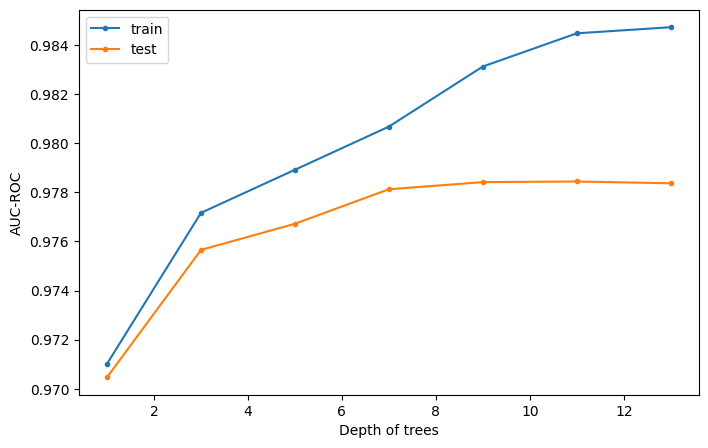

In [22]:
depth = list(range(1, 14, 2))
n_trees = 50
quals_train = []
quals_test = []
for d in tqdm(depth):
    lgb = LGBMClassifier(n_estimators=n_trees, max_depth=d, n_jobs=1, **lgb_params)
    lgb.fit(X_train_lgb, y_train)
    q_train = roc_auc_score(y_train, lgb.predict_proba(X_train_lgb)[:, 1])
    q_test = roc_auc_score(y_test, lgb.predict_proba(X_test_lgb)[:, 1])
    quals_train.append(q_train)
    quals_test.append(q_test)

plt.figure(figsize=(8, 5))
plt.plot(depth, quals_train, marker='.', label='train')
plt.plot(depth, quals_test, marker='.', label='test')
plt.xlabel('Depth of trees')
plt.ylabel('AUC-ROC')
plt.legend()

plt.show()

И сравним с CatBoost:


100%|██████████| 7/7 [00:15<00:00,  2.25s/it]


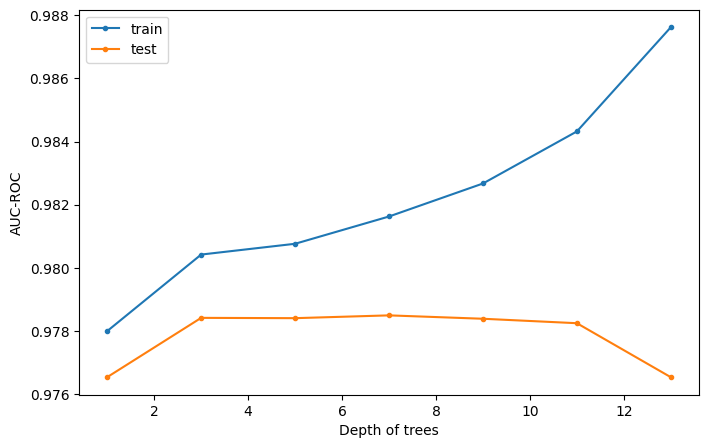

In [23]:
depth = list(range(1, 14, 2))
n_trees = 50
quals_train = []
quals_test = []
for d in tqdm(depth):
    clf = CatBoostClassifier(n_estimators=n_trees, max_depth=d,
                             cat_features=['gender', 'smoking_history'],
                             logging_level="Silent")

    clf.fit(X_train_cat, y_train)
    q_train = roc_auc_score(y_train, clf.predict_proba(X_train_cat)[:, 1])
    q_test = roc_auc_score(y_test, clf.predict_proba(X_test_cat)[:, 1])
    quals_train.append(q_train)
    quals_test.append(q_test)

plt.figure(figsize=(8, 5))
plt.plot(depth, quals_train, marker='.', label='train')
plt.plot(depth, quals_test, marker='.', label='test')
plt.xlabel('Depth of trees')
plt.ylabel('AUC-ROC')
plt.legend()

plt.show()

Теперь, когда у нас есть отличные модели, нужно их сохранить!


In [24]:
clf_lgb.booster_.save_model('lightgbm.txt')

clf.save_model('catboost.cbm', format='cbm')

И загрузим их обратно, когда нам нужно будет их применить:


In [25]:
lgb = LGBMClassifier(model_file='mode.txt')

clf = clf.load_model('catboost.cbm')

## Блендинг


Как было описано на лекции, блендинг — это «мета-алгоритм», предсказание которого строится как взвешенная сумма базовых алгоритмов. Рассмотрим простой пример блендинга бустинга и линейной регрессии.


In [26]:
!wget https://github.com/darkydash/ml_hse_2024/raw/refs/heads/main/week09/boston.pkl

--2026-10-28 20:04:26--  https://github.com/darkydash/ml_hse_2024/raw/refs/heads/main/week09/boston.pkl
Resolving github.com (github.com)... 140.82.112.4
Connecting to github.com (github.com)|140.82.112.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/darkydash/ml_hse_2024/refs/heads/main/week09/boston.pkl [following]
--2026-10-28 20:04:26--  https://raw.githubusercontent.com/darkydash/ml_hse_2024/refs/heads/main/week09/boston.pkl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 59783 (58K) [application/octet-stream]
Saving to: ‘boston.pkl’

boston.pkl          100%[===================>]  58.38K  --.-KB/s    in 0.01s   

2026-10-28 20:04:26 (4.95 MB/s) - ‘boston.pkl’ saved [59783/59783]



In [27]:
#from sklearn.datasets import load_boston
import pickle


data = pickle.load(open('boston.pkl', 'rb'))
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

def rmse(y_true, y_pred):
    error = (y_true - y_pred) ** 2
    return np.sqrt(np.mean(error))

In [28]:
from catboost import CatBoostRegressor

cbm = CatBoostRegressor(
    iterations=100, max_depth=4, learning_rate=0.01,
    loss_function='RMSE', logging_level='Silent'
)
cbm.fit(X_train, y_train)

y_pred_cbm = cbm.predict(X_test)
y_train_pred_cbm = cbm.predict(X_train)

print("Train RMSE GB = %.4f" % rmse(y_train, y_train_pred_cbm))
print("Test RMSE GB = %.4f" % rmse(y_test, y_pred_cbm))

Train RMSE GB = 5.4431
Test RMSE GB = 6.5456


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_train_pred_lr = lr.predict(X_train_scaled)

print("Train RMSE LR = %.4f" % rmse(y_train, y_train_pred_lr))
print("Test RMSE LR = %.4f" % rmse(y_test, y_pred_lr))

Train RMSE LR = 4.4113
Test RMSE LR = 5.4154


Для простоты предположим, что новый алгоритм $a(x)$ представлен как
$$
    a(x)
    =
    \sum_{n = 1}^{N}
    w_n b_n(x),
$$
где $\sum_{n} w_n =1$


In [30]:
def select_weights(y_true, y_pred_1, y_pred_2):
    grid = np.linspace(0, 1, 1000)
    metric = []
    for w_0 in grid:
        w_1 = 1 - w_0
        y_a = w_0 * y_pred_1 + w_1 * y_pred_2
        metric.append([rmse(y_true, y_a), w_0, w_1])
    return metric

In [31]:
rmse_blending_train, w_0, w_1 = min(
    select_weights(y_train, y_train_pred_cbm, y_train_pred_lr),
    key=lambda x: x[0]
)

In [32]:
# RMSE на обучении

rmse_blending_train

np.float64(4.273424051954005)

In [33]:
# RMSE на тесте

rmse(y_test, y_pred_cbm * w_0 +  y_pred_lr * w_1)

np.float64(5.237314717927903)

В результате мы получаем лучшее качество на тестовой выборке, чем каждый алгоритм по отдельности.
